In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import time

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
files = {}

for name in ["X_train", "X_test", "y_train", "y_test"]:
    matches = glob.glob(
        f"/kaggle/input/**/{name}.csv",
        recursive=True
    )

    if not matches:
        raise FileNotFoundError(f"{name}.csv not found!")

    files[name] = matches[0]

X_train = pd.read_csv(files["X_train"]).values
X_test = pd.read_csv(files["X_test"]).values

y_train = pd.read_csv(files["y_train"]).values.ravel()
y_test = pd.read_csv(files["y_test"]).values.ravel()

print("Data loaded successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Data loaded successfully!
X_train: (8929, 50)
X_test: (2233, 50)


In [3]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    return -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

In [4]:
def stochastic_gradient_descent(
    X, y, learning_rate=0.01, epochs=100
):
    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    loss_history = []

    for epoch in range(epochs):

        # Shuffle training data
        indices = np.random.permutation(n_samples)

        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for i in range(n_samples):

            x_i = X_shuffled[i]
            y_i = y_shuffled[i]

            # Forward pass
            z = np.dot(x_i, weights) + bias
            y_pred = sigmoid(z)

            # Calculate gradients
            error = y_pred - y_i

            dw = x_i * error
            db = error

            # Update parameters
            weights -= learning_rate * dw
            bias -= learning_rate * db

        # Calculate loss after each epoch
        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)

        loss_history.append(loss)

    return weights, bias, loss_history


print("SGD algorithm created successfully!")

SGD algorithm created successfully!


In [5]:
start_time = time.time()

weights_sgd, bias_sgd, loss_history_sgd = (
    stochastic_gradient_descent(
        X_train,
        y_train,
        learning_rate=0.01,
        epochs=100
    )
)

training_time_sgd = time.time() - start_time

print("SGD Training Completed!")
print("Final Training Loss:", loss_history_sgd[-1])
print("Training Time:", round(training_time_sgd, 4))

SGD Training Completed!
Final Training Loss: 0.577290793413598
Training Time: 12.3348


In [6]:
def predict(X, weights, bias, threshold=0.5):
    probabilities = sigmoid(np.dot(X, weights) + bias)
    return (probabilities >= threshold).astype(int)


y_pred_sgd = predict(X_test, weights_sgd, bias_sgd)

print("Predictions generated successfully!")

Predictions generated successfully!


In [7]:
accuracy_sgd = accuracy_score(y_test, y_pred_sgd)
precision_sgd = precision_score(y_test, y_pred_sgd)
recall_sgd = recall_score(y_test, y_pred_sgd)
f1_sgd = f1_score(y_test, y_pred_sgd)

print("Stochastic Gradient Descent Results")
print("-----------------------------------")
print("Accuracy:", round(accuracy_sgd, 4))
print("Precision:", round(precision_sgd, 4))
print("Recall:", round(recall_sgd, 4))
print("F1-Score:", round(f1_sgd, 4))
print("Training Time:", round(training_time_sgd, 4))

Stochastic Gradient Descent Results
-----------------------------------
Accuracy: 0.6932
Precision: 0.766
Recall: 0.5076
F1-Score: 0.6106
Training Time: 12.3348


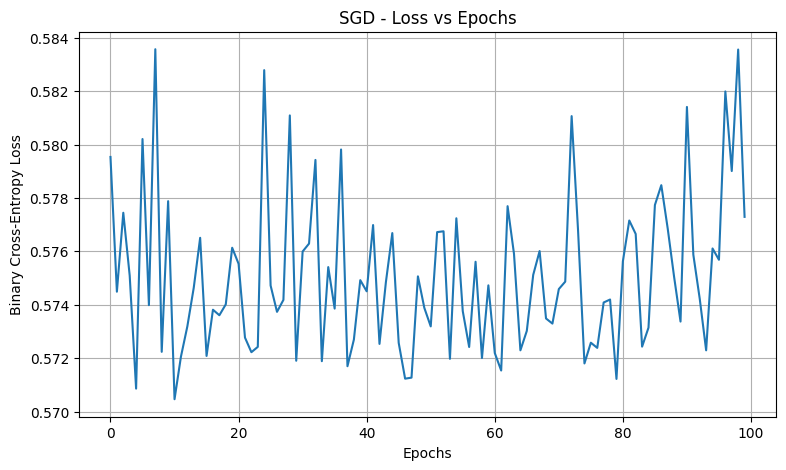

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(loss_history_sgd)

plt.title("SGD - Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

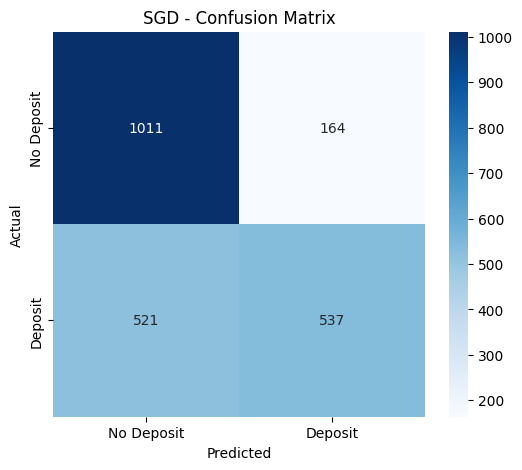

In [9]:
cm = confusion_matrix(y_test, y_pred_sgd)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Deposit", "Deposit"],
    yticklabels=["No Deposit", "Deposit"]
)

plt.title("SGD - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()